In [2]:
import cv2
import torch
import time
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from ultralytics import YOLO
from IPython.display import Video, display

In [3]:
PROJECT_DIR = Path("..")

VIDEO_DIR = PROJECT_DIR / "sample_videos"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "videos"
MODEL_DIR = PROJECT_DIR / "models"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Video folder:", VIDEO_DIR)
print("Output folder:", OUTPUT_DIR)

Video folder: ..\sample_videos
Output folder: ..\outputs\videos


In [4]:
model_path = MODEL_DIR / "yolov8n.pt"

model = YOLO(str(model_path))

print("YOLOv8 model loaded successfully!")

YOLOv8 model loaded successfully!


In [5]:
print(VIDEO_DIR)

..\sample_videos


In [6]:
video_path = VIDEO_DIR / "traffic.mp4"

cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise FileNotFoundError(f"Cannot open video: {video_path}")

print("Video opened successfully!")

Video opened successfully!


In [7]:
fps = cap.get(cv2.CAP_PROP_FPS)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))

height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = total_frames / fps if fps > 0 else 0

print("FPS:", fps)
print("Total Frames:", total_frames)
print("Width:", width)
print("Height:", height)
print("Duration:", round(duration, 2), "seconds")

cap.release()

FPS: 29.97002997002997
Total Frames: 302
Width: 1280
Height: 720
Duration: 10.08 seconds


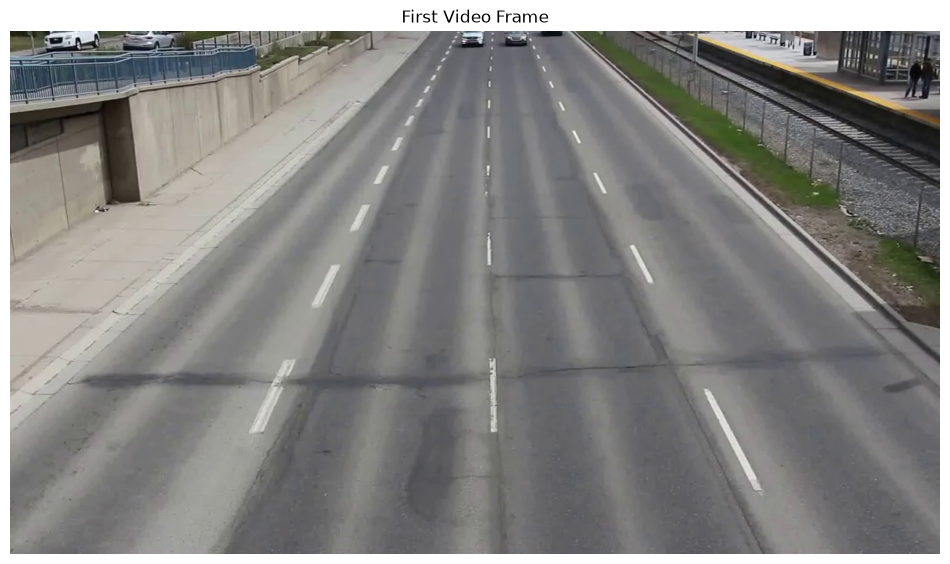

In [8]:
cap = cv2.VideoCapture(str(video_path))

ret, frame = cap.read()

cap.release()

if ret:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 7))
    plt.imshow(frame_rgb)
    plt.title("First Video Frame")
    plt.axis("off")
    plt.show()
else:
    print("Could not read video frame.")

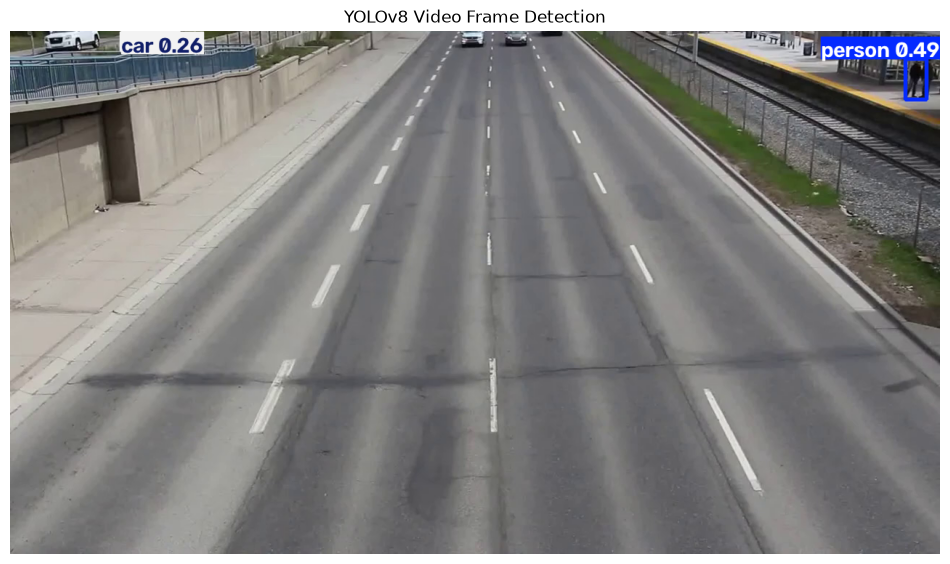

In [9]:
results = model.predict(
    source=frame,
    conf=0.25,
    imgsz=640,
    verbose=False
)

result = results[0]

annotated_frame = result.plot()

annotated_rgb = cv2.cvtColor(
    annotated_frame,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))
plt.imshow(annotated_rgb)
plt.title("YOLOv8 Video Frame Detection")
plt.axis("off")
plt.show()

In [10]:
input_video = str(video_path)

output_video = str(
    OUTPUT_DIR / "traffic_detected.mp4"
)

cap = cv2.VideoCapture(input_video)

if not cap.isOpened():
    raise FileNotFoundError("Could not open input video.")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

if fps <= 0:
    fps = 30.0

# MP4 video writer
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    output_video,
    fourcc,
    fps,
    (width, height)
)

if not out.isOpened():
    cap.release()
    raise RuntimeError("Could not create output video.")

frame_count = 0
total_detections = 0

start_time = time.time()

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    # YOLO prediction
    results = model.predict(
        source=frame,
        conf=0.25,
        imgsz=640,
        verbose=False
    )

    result = results[0]

    # Draw bounding boxes
    annotated_frame = result.plot()

    # Write processed frame
    out.write(annotated_frame)

    frame_count += 1
    total_detections += len(result.boxes)

    if frame_count % 50 == 0:
        print("Processed frames:", frame_count)

cap.release()
out.release()

end_time = time.time()

processing_time = end_time - start_time

processing_fps = (
    frame_count / processing_time
    if processing_time > 0 else 0
)

print("\nVIDEO PROCESSING COMPLETED")
print("--------------------------")
print("Frames processed:", frame_count)
print("Total detections across frames:", total_detections)
print("Processing time:", round(processing_time, 2), "seconds")
print("Processing FPS:", round(processing_fps, 2))
print("Output saved:", output_video)

Processed frames: 50
Processed frames: 100
Processed frames: 150
Processed frames: 200
Processed frames: 250
Processed frames: 300

VIDEO PROCESSING COMPLETED
--------------------------
Frames processed: 302
Total detections across frames: 3092
Processing time: 24.88 seconds
Processing FPS: 12.14
Output saved: ..\outputs\videos\traffic_detected.mp4


In [11]:
display(
    Video(
        output_video,
        embed=True,
        width=800
    )
)

In [12]:
from collections import Counter

cap = cv2.VideoCapture(input_video)

object_counts = Counter()

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    results = model.predict(
        source=frame,
        conf=0.25,
        verbose=False
    )

    result = results[0]

    class_ids = (
        result.boxes.cls.cpu().numpy().astype(int)
    )

    for class_id in class_ids:
        object_name = model.names[class_id]
        object_counts[object_name] += 1

cap.release()

print("VIDEO OBJECT DETECTION REPORT")
print("-----------------------------")

for name, count in object_counts.items():
    print(f"{name}: {count}")

print("-----------------------------")
print("Total detections:", sum(object_counts.values()))

VIDEO OBJECT DETECTION REPORT
-----------------------------
person: 153
car: 2819
truck: 25
bus: 37
train: 58
-----------------------------
Total detections: 3092


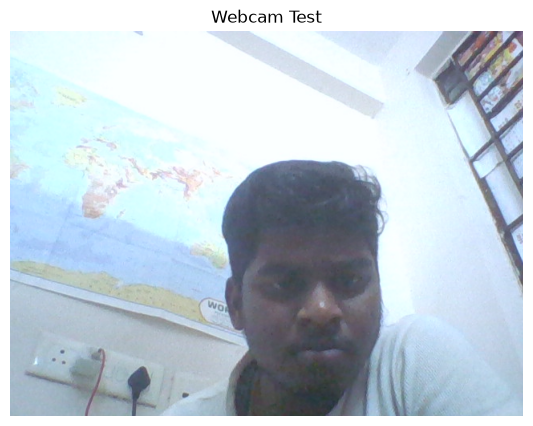

In [13]:
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError(
        "Webcam not detected. Check camera permissions or camera index."
    )

ret, frame = cap.read()

if ret:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 5))
    plt.imshow(frame_rgb)
    plt.title("Webcam Test")
    plt.axis("off")
    plt.show()

cap.release()

In [ ]:
webcam_output = str(
    OUTPUT_DIR / "webcam_detected.mp4"
)

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Could not open webcam.")

# Set capture resolution
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

fps = 30.0
max_frames = 300

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    webcam_output,
    fourcc,
    fps,
    (width, height)
)

if not out.isOpened():
    cap.release()
    raise RuntimeError("Could not create webcam output video.")

frame_count = 0

try:
    while frame_count < max_frames:

        ret, frame = cap.read()

        if not ret:
            print("Unable to capture frame.")
            break

        results = model.predict(
            source=frame,
            conf=0.25,
            imgsz=640,
            verbose=False
        )

        annotated_frame = results[0].plot()

        out.write(annotated_frame)

        frame_count += 1

        if frame_count % 30 == 0:
            print("Captured frames:", frame_count)

finally:
    cap.release()
    out.release()

print("Webcam recording saved:", webcam_output)

Captured frames: 30
Captured frames: 60
Captured frames: 90
Captured frames: 120
Captured frames: 150
Captured frames: 180
Captured frames: 210
Captured frames: 240
Captured frames: 270
Captured frames: 300
Webcam recording saved: ..\outputs\videos\webcam_detected.mp4


In [19]:


cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Could not open webcam.")

try:
    while True:

        ret, frame = cap.read()

        if not ret:
            break

        # Rotate webcam video 90 degrees to the right
        frame = cv2.flip(frame, 1)

        start = time.time()

        results = model.predict(
            source=frame,
            conf=0.25,
            imgsz=640,
            verbose=False
        )

        annotated_frame = results[0].plot()

        end = time.time()

        fps = 1 / (end - start) if end > start else 0

        cv2.putText(
            annotated_frame,
            f"FPS: {fps:.2f}",
            (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (0, 255, 0),
            2
        )

        cv2.imshow(
            "YOLOv8 Real-Time Object Detection",
            annotated_frame
        )

        # Press q to stop
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

In [16]:
video_path1 = VIDEO_DIR / "trff.mp4"

cap = cv2.VideoCapture(str(video_path1))

if not cap.isOpened():
    raise FileNotFoundError(f"Cannot open video: {video_path1}")

print("Video opened successfully!")

Video opened successfully!


In [17]:
input_video = str(video_path1)

output_video = str(
    OUTPUT_DIR / "traffic_detect.mp4"
)

cap = cv2.VideoCapture(input_video)

if not cap.isOpened():
    raise FileNotFoundError("Could not open input video.")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

if fps <= 0:
    fps = 30.0

# MP4 video writer
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    output_video,
    fourcc,
    fps,
    (width, height)
)

if not out.isOpened():
    cap.release()
    raise RuntimeError("Could not create output video.")

frame_count = 0
total_detections = 0

start_time = time.time()

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    # YOLO prediction
    results = model.predict(
        source=frame,
        conf=0.25,
        imgsz=640,
        verbose=False
    )

    result = results[0]

    # Draw bounding boxes
    annotated_frame = result.plot()

    # Write processed frame
    out.write(annotated_frame)

    frame_count += 1
    total_detections += len(result.boxes)

    if frame_count % 50 == 0:
        print("Processed frames:", frame_count)

cap.release()
out.release()

end_time = time.time()

processing_time = end_time - start_time

processing_fps = (
    frame_count / processing_time
    if processing_time > 0 else 0
)

print("\nVIDEO PROCESSING COMPLETED")
print("--------------------------")
print("Frames processed:", frame_count)
print("Total detections across frames:", total_detections)
print("Processing time:", round(processing_time, 2), "seconds")
print("Processing FPS:", round(processing_fps, 2))
print("Output saved:", output_video)

Processed frames: 50
Processed frames: 100
Processed frames: 150
Processed frames: 200
Processed frames: 250
Processed frames: 300
Processed frames: 350
Processed frames: 400
Processed frames: 450
Processed frames: 500
Processed frames: 550
Processed frames: 600
Processed frames: 650
Processed frames: 700
Processed frames: 750
Processed frames: 800
Processed frames: 850
Processed frames: 900

VIDEO PROCESSING COMPLETED
--------------------------
Frames processed: 922
Total detections across frames: 24741
Processing time: 82.9 seconds
Processing FPS: 11.12
Output saved: ..\outputs\videos\traffic_detect.mp4
